# Autoregressive rollout evaluation

rollout条件とGTデータを確認してから自己回帰推論を実行し、誤差成長と保存済み画像・ParaView出力を可視化します。YAMLはNotebookから変更しません。


## 1. 使用する設定


In [1]:
from pathlib import Path
import csv, subprocess, sys
import matplotlib.pyplot as plt
import yaml
from IPython.display import Image, Markdown, display

def find_project_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs").is_dir() and (candidate / "performance").is_dir():
            return candidate
    raise FileNotFoundError("FNOV2リポジトリ内からNotebookを開いてください。")

def resolve(value, config_path):
    path = Path(value)
    return path.resolve() if path.is_absolute() else (config_path.parent / path).resolve()

def status(ok, label, detail=""):
    mark = "✅" if ok else "❌"
    print(f"{mark} {label}" + (f": {detail}" if detail else ""))
    return ok

ROOT = find_project_root(Path.cwd())
print("project:", ROOT)
################################
EXPERIMENT_ID = "ex003_baseline"
################################
print("experiment:", EXPERIMENT_ID)
ROLLOUT_YAML = ROOT / "performance/configs/rollout.yaml"
cfg=yaml.safe_load(ROLLOUT_YAML.read_text(encoding="utf-8"))
loader_path=resolve(cfg["test_dataloader_config"],ROLLOUT_YAML)
loader=yaml.safe_load(loader_path.read_text(encoding="utf-8"))
kind=loader["evaluation"]["type"]
data_dir=resolve(loader["data"]["directory"],loader_path)
checkpoint=resolve(cfg["checkpoint"],ROLLOUT_YAML)
result_dir=resolve(cfg["output"]["root_directory"],ROLLOUT_YAML)/kind/"rollout"


project: /workspace/FNOV2
experiment: ex003_baseline


## 2. 設定の可視化


In [2]:
summary={
 "evaluation":kind,"data directory":str(data_dir),"loader test Re":loader["test_re"],
 "rollout Re":cfg["rollout"]["reynolds"],"start/end":[cfg["rollout"]["start_time"],cfg["rollout"]["end_time"]],
 "steps":cfg["rollout"]["steps"],"checkpoint":str(checkpoint),"W&B":cfg["wandb"],"output":str(result_dir),
}
print(yaml.safe_dump(summary,allow_unicode=True,sort_keys=False))
display(Markdown("### rollout.yaml")); print(ROLLOUT_YAML.read_text(encoding="utf-8"))
display(Markdown("### test_dataloader.yaml")); print(loader_path.read_text(encoding="utf-8"))


evaluation: interpolation
data directory: /workspace/FNOV2/performance/data/interpolation/processed/pairs
loader test Re:
- 35
- 85
- 135
- 185
- 235
rollout Re:
- 35
- 85
- 135
- 185
- 235
start/end:
- 340.0
- 350.0
steps: 100
checkpoint: /workspace/FNOV2/outputs/training/ex003/best.pt
W&B:
  enabled: true
  project: fnov2-cylinder-wake
  entity: null
  name_prefix: rollout
  group: performance-rollout
  mode: online
output: /workspace/FNOV2/performance/results/ex003_baseline/interpolation/rollout



### rollout.yaml

test_dataloader_config: test_dataloader.yaml
model_config: ../../configs/model.yaml
###モデル切り替え↓
checkpoint: ../../outputs/training/ex003/best.pt
device: auto
rollout:
  start_time: 340.0
  end_time: 350.0
  steps: 100
  tolerance: 0.000001
  reynolds: [35,85,135,185,235]  # sanity後に内挿全Re、外挿全Reへ広げる。(例reynolds: [35, 85, 135, 185, 235])
output:
  #########################################
  root_directory: ../results/ex003_baseline
  #########################################
  metrics_csv: rollout_metrics.csv
  representative_count: 5
  save_prediction_only_pt: true
  export_vti: true
wandb:
  enabled: true
  project: fnov2-cylinder-wake
  entity: null
  name_prefix: rollout
  group: performance-rollout
  mode: online



### test_dataloader.yaml

# interpolation / extrapolationはこのconfigだけで切り替える。
evaluation:
  type: interpolation

data:
  directory: ../data/interpolation/processed/pairs
  file_pattern: "pairs_case*_Re*.pt"

test_re:
  - 35
  - 85
  - 135
  - 185
  - 235

# channel構成とtrain統計量、および共通loader設定の正本。
dataset_config: ../../configs/dataset.yaml
dataloader_config: ../../configs/dataloader.yaml



## 3. 実行前チェック


In [3]:
files=sorted(data_dir.glob(loader["data"]["file_pattern"]))
available=set()
for path in files:
    try: available.add(float(path.stem.rsplit("_Re",1)[1]))
    except (IndexError,ValueError): pass
requested={float(v) for v in cfg["rollout"]["reynolds"]}
loader_re={float(v) for v in loader["test_re"]}
performance_root=(ROOT/"performance/data"/kind).resolve()
r=cfg["rollout"]
expected_end=float(r["start_time"])+int(r["steps"])*(float(r["end_time"])-float(r["start_time"]))/int(r["steps"])
checks=[
 status(ROLLOUT_YAML.is_file(),"rollout config",ROLLOUT_YAML),
 status(loader_path.is_file(),"test dataloader config",loader_path),
 status(checkpoint.is_file(),"checkpoint",checkpoint),
 status(data_dir.is_dir(),"performance data directory",data_dir),
 status(data_dir.is_relative_to(performance_root),"data isolation",performance_root),
 status(requested.issubset(loader_re),"rollout Re in test_re",f"requested={sorted(requested)}"),
 status(requested.issubset(available),"rollout Re files",f"available={sorted(available)}"),
 status(abs(expected_end-float(r["end_time"]))<=float(r["tolerance"]),"time/step consistency"),
 status(result_dir.parents[1].name==EXPERIMENT_ID,"experiment result root",result_dir.parents[1]),
]
PRECHECK_OK=all(checks)
print("\n実行可能" if PRECHECK_OK else "\n設定またはデータを修正してください。")


✅ rollout config: /workspace/FNOV2/performance/configs/rollout.yaml
✅ test dataloader config: /workspace/FNOV2/performance/configs/test_dataloader.yaml
✅ checkpoint: /workspace/FNOV2/outputs/training/ex003/best.pt
✅ performance data directory: /workspace/FNOV2/performance/data/interpolation/processed/pairs
✅ data isolation: /workspace/FNOV2/performance/data/interpolation
✅ rollout Re in test_re: requested=[35.0, 85.0, 135.0, 185.0, 235.0]
✅ rollout Re files: available=[35.0, 85.0, 135.0, 185.0, 235.0]
✅ time/step consistency
✅ experiment result root: /workspace/FNOV2/performance/results/ex003_baseline

実行可能


## 4. Rollout実行


In [4]:
RUN_ROLLOUT = True
if RUN_ROLLOUT:
    if not PRECHECK_OK: raise RuntimeError("事前チェックが失敗しています。")
    subprocess.run([sys.executable,str(ROOT/"performance/src/rollout.py"),"--config",str(ROLLOUT_YAML)],cwd=ROOT,check=True)
else: print("未実行。確認後にRUN_ROLLOUT=Trueへ変更してください。")


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /root/.netrc.
wandb: Currently logged in as: sotaron9012 (str-kit) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: setting up run yff0zh2b
wandb: Tracking run with wandb version 0.28.2
wandb: Run data is saved locally in /workspace/FNOV2/wandb/run-20261016_131954-yff0zh2b
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run rollout-Re35
wandb: ⭐️ View project at https://wandb.ai/str-kit/fnov2-cylinder-wake
wandb: 🚀 View run at https://wandb.ai/str-kit/fnov2-cylinder-wake/runs/yff0zh2b
wandb: updating run metadata
wandb: uploading wandb-metadata.json; uploading requirements.txt; uploading wandb-summary.json; uploading config.yaml
wandb: uploading history steps 0-99, summary
wandb: 
wandb: Run history:
wandb:                  Re ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:        elapsed_time ▁▁▁▁▂▂▂▂▂▃▃▃▃▄▄▄▄▄▄▄▅▅▅▅▅▆▆▆▆▆▇▇▇▇▇▇▇▇██
wandb:         mse_overall ▁▁▁▁▁▁▁▁▁▁▁▁

rollout completed: Re=[35.0, 85.0, 135.0, 185.0, 235.0], results=/workspace/FNOV2/performance/results/ex003_baseline/interpolation/rollout


## 5. Re別の誤差成長


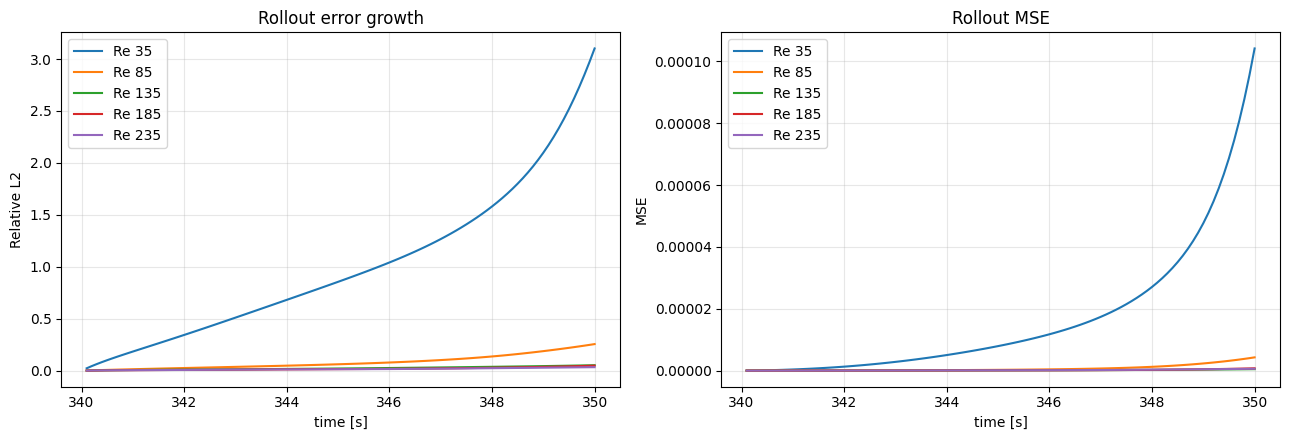

In [5]:
metrics_path=result_dir/cfg["output"]["metrics_csv"]
if not metrics_path.exists(): print("結果がありません:",metrics_path)
else:
 with metrics_path.open(encoding="utf-8",newline="") as f: rows=list(csv.DictReader(f))
 grouped={}
 for row in rows: grouped.setdefault(float(row["Re"]),[]).append(row)
 fig,axes=plt.subplots(1,2,figsize=(13,4.5))
 for re_value,values in sorted(grouped.items()):
  t=[float(v["time"]) for v in values]
  axes[0].plot(t,[float(v["relative_l2_overall"]) for v in values],label=f"Re {re_value:g}")
  axes[1].plot(t,[float(v["mse_overall"]) for v in values],label=f"Re {re_value:g}")
 axes[0].set(xlabel="time [s]",ylabel="Relative L2",title="Rollout error growth")
 axes[1].set(xlabel="time [s]",ylabel="MSE",title="Rollout MSE")
 for ax in axes: ax.grid(alpha=.3); ax.legend()
 plt.tight_layout(); plt.show()


## 6. GT / Prediction / Absolute Error画像

表示するReを変更してセルを再実行できます。既にPNGとして保存された画像をNotebook内へ表示します。


Re 35: 15 images


### max_error_p

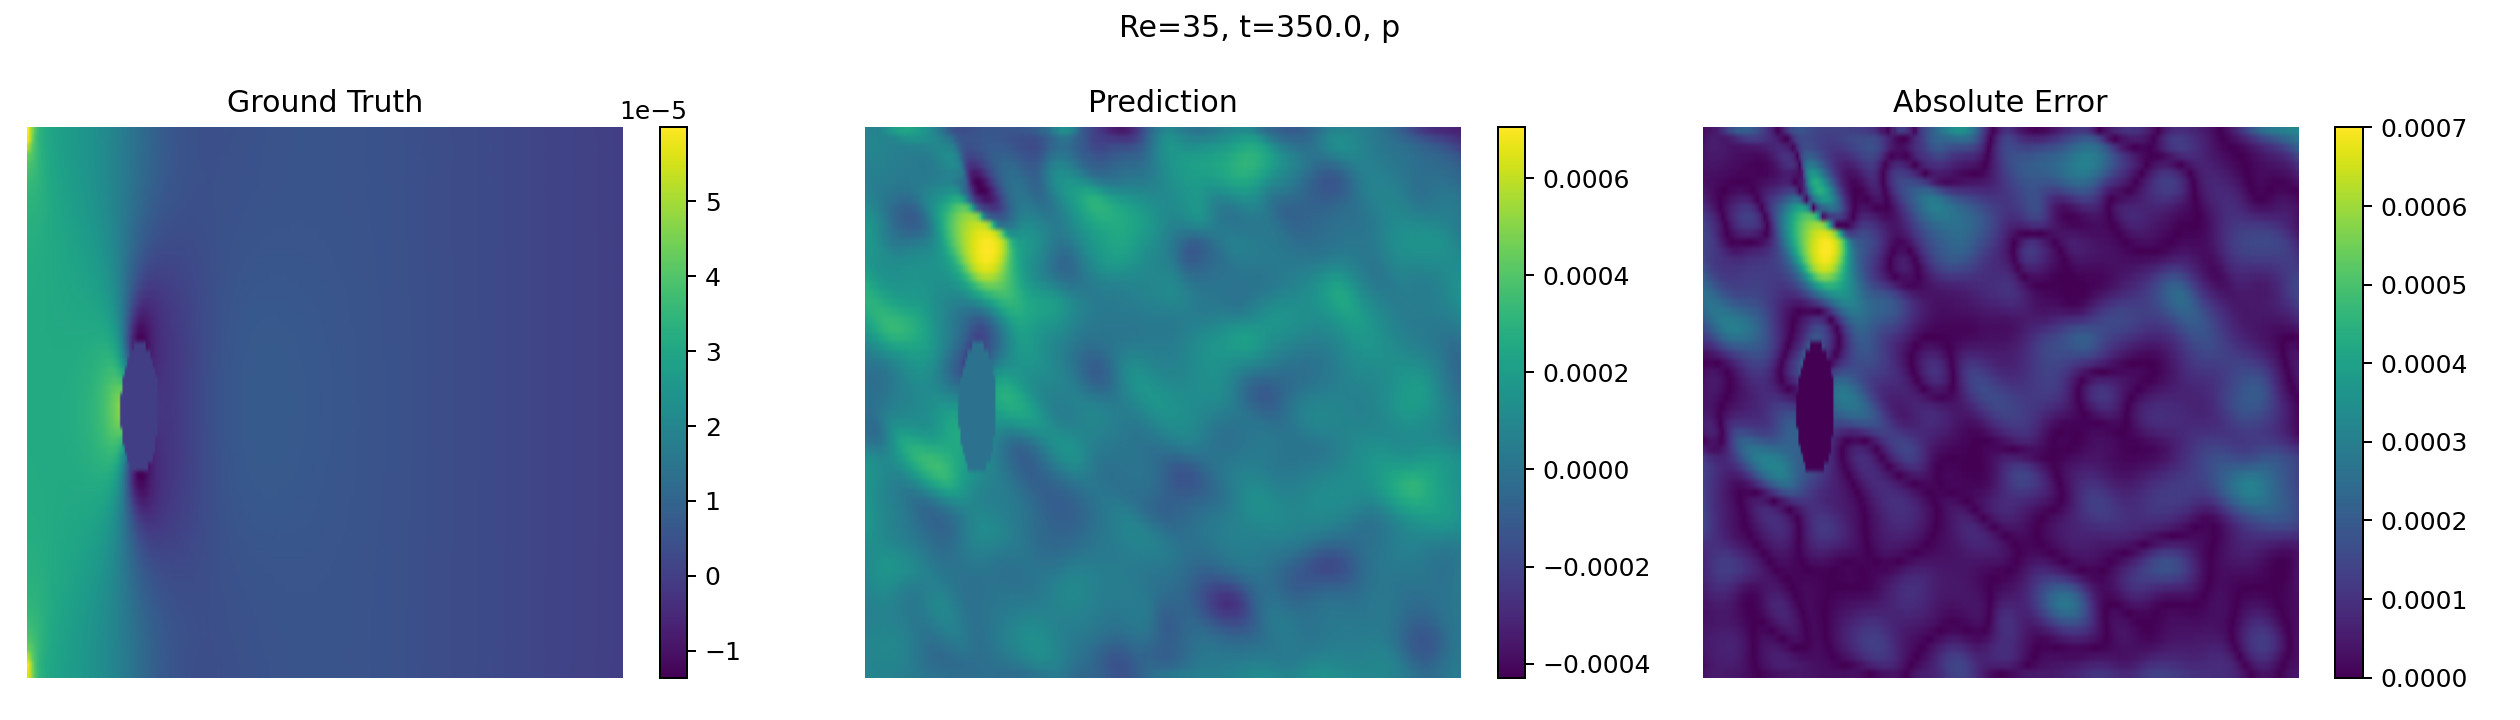

### max_error_u

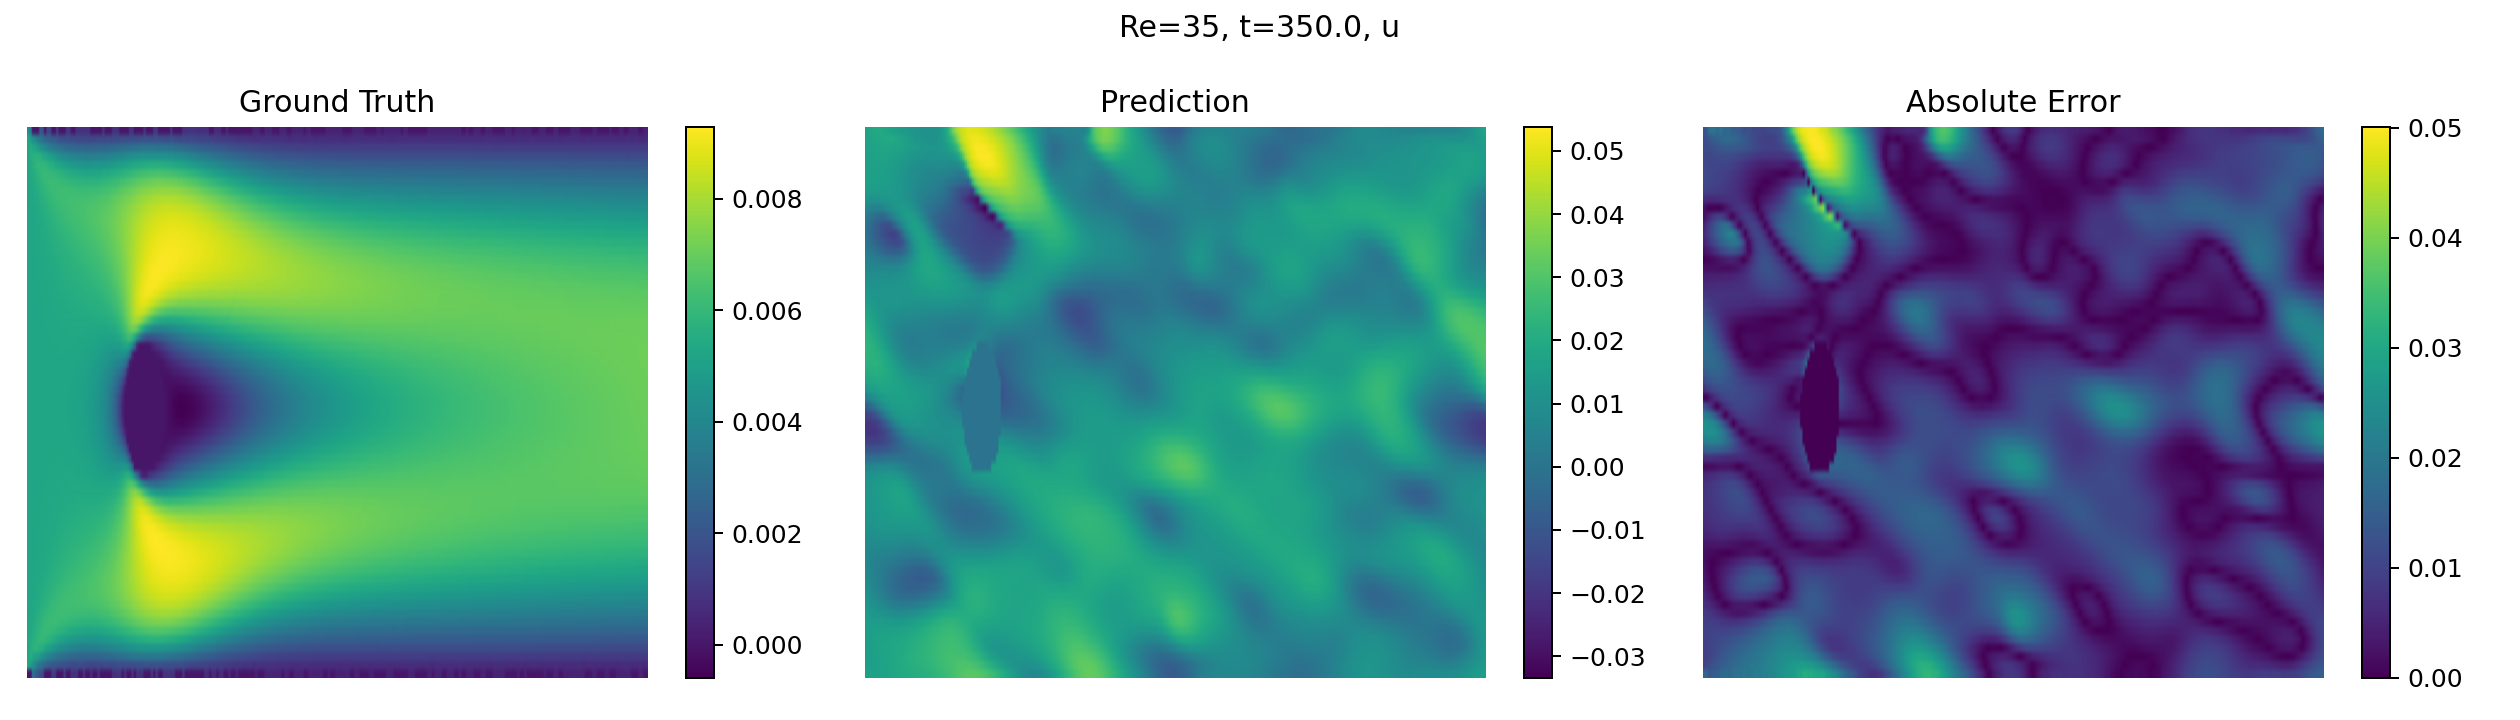

### max_error_v

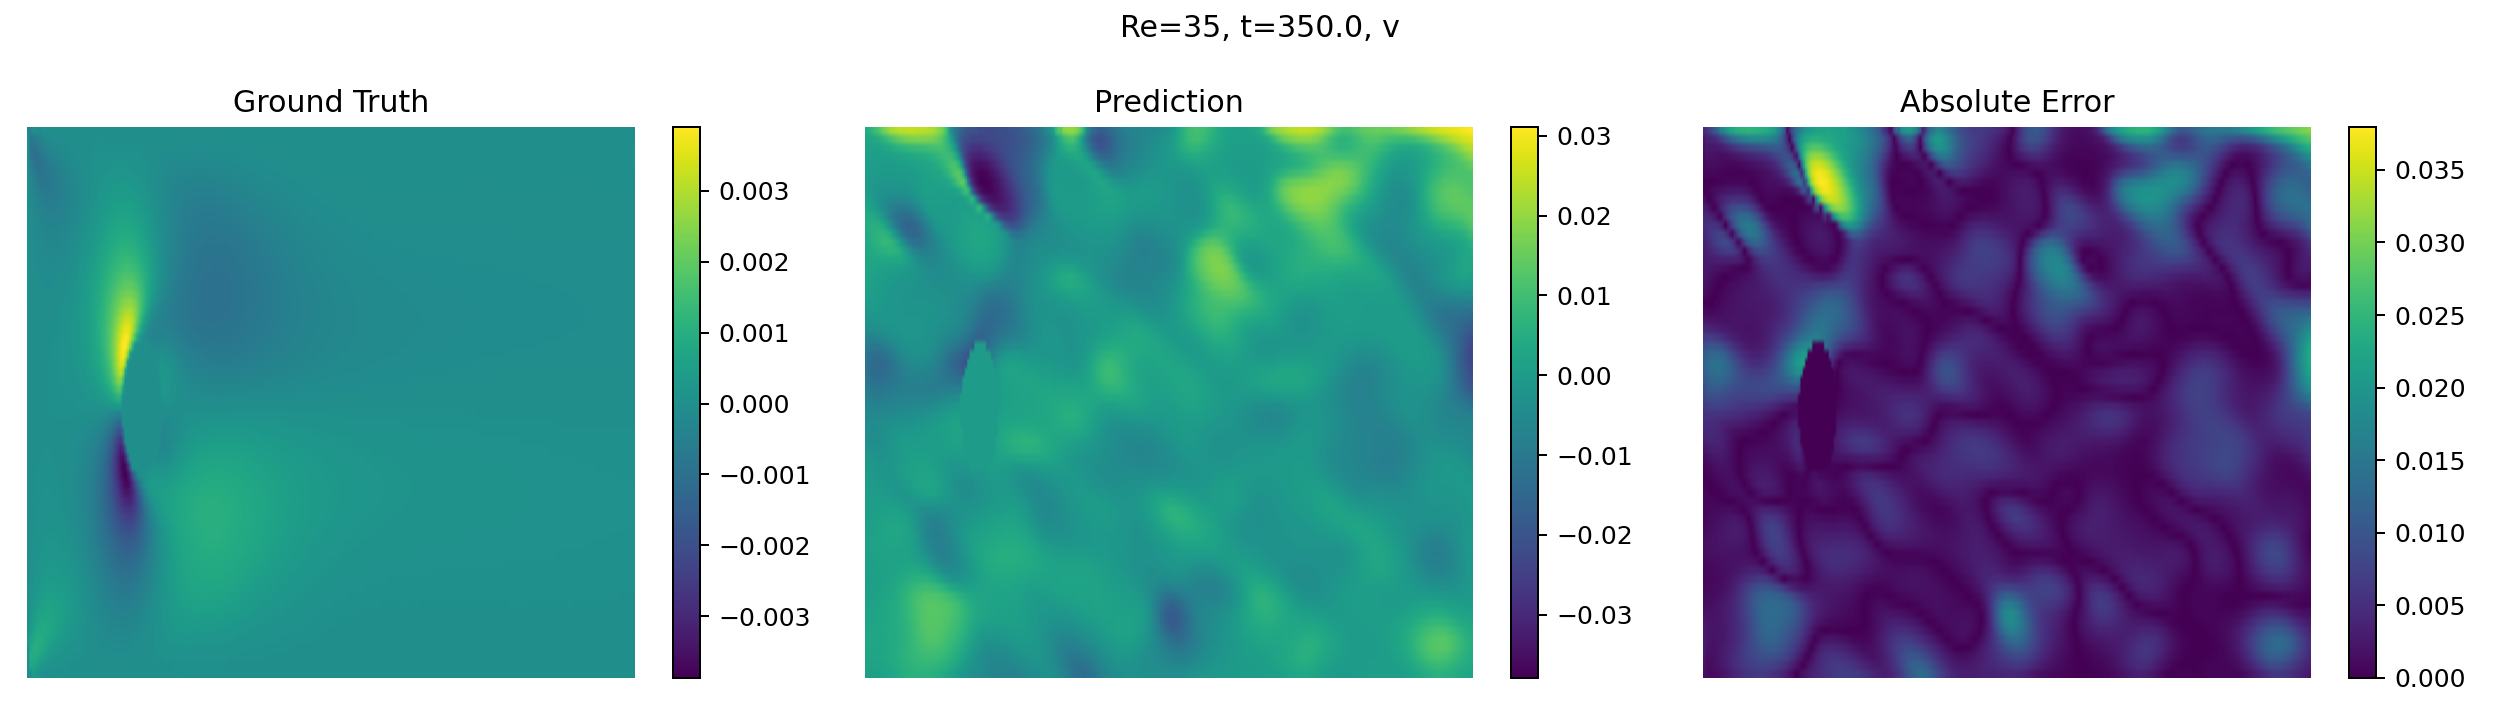

### step001_p

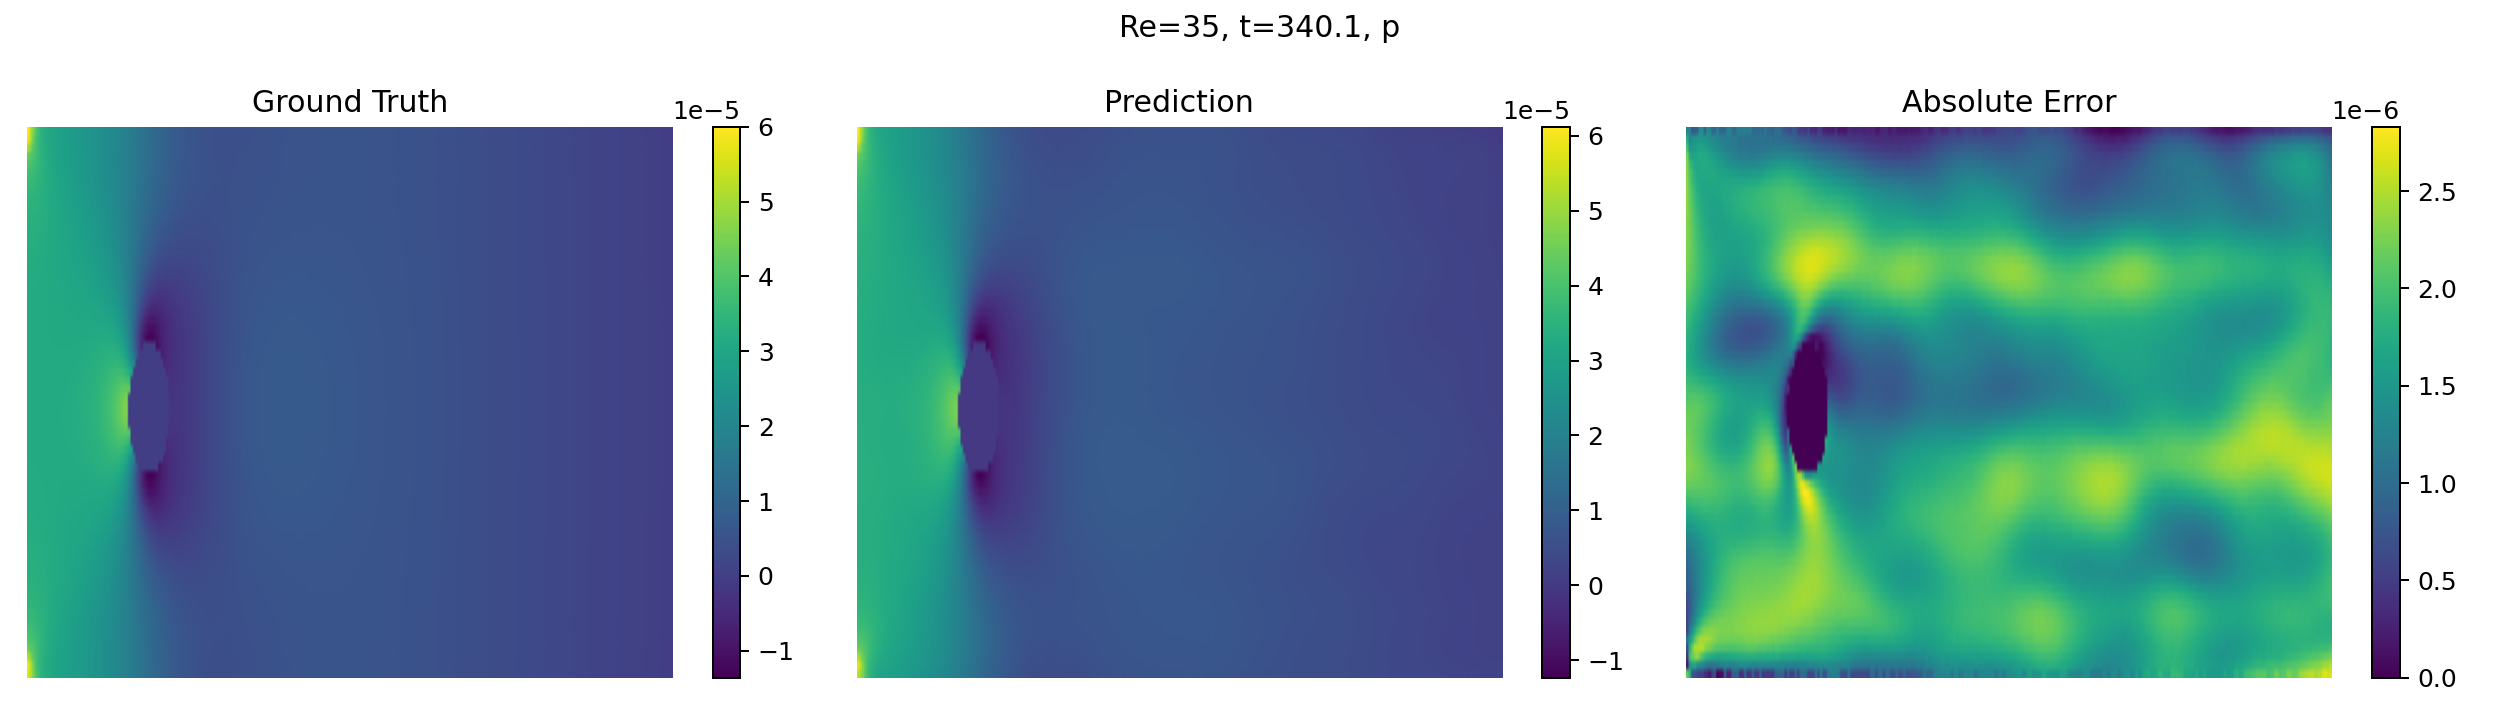

### step001_u

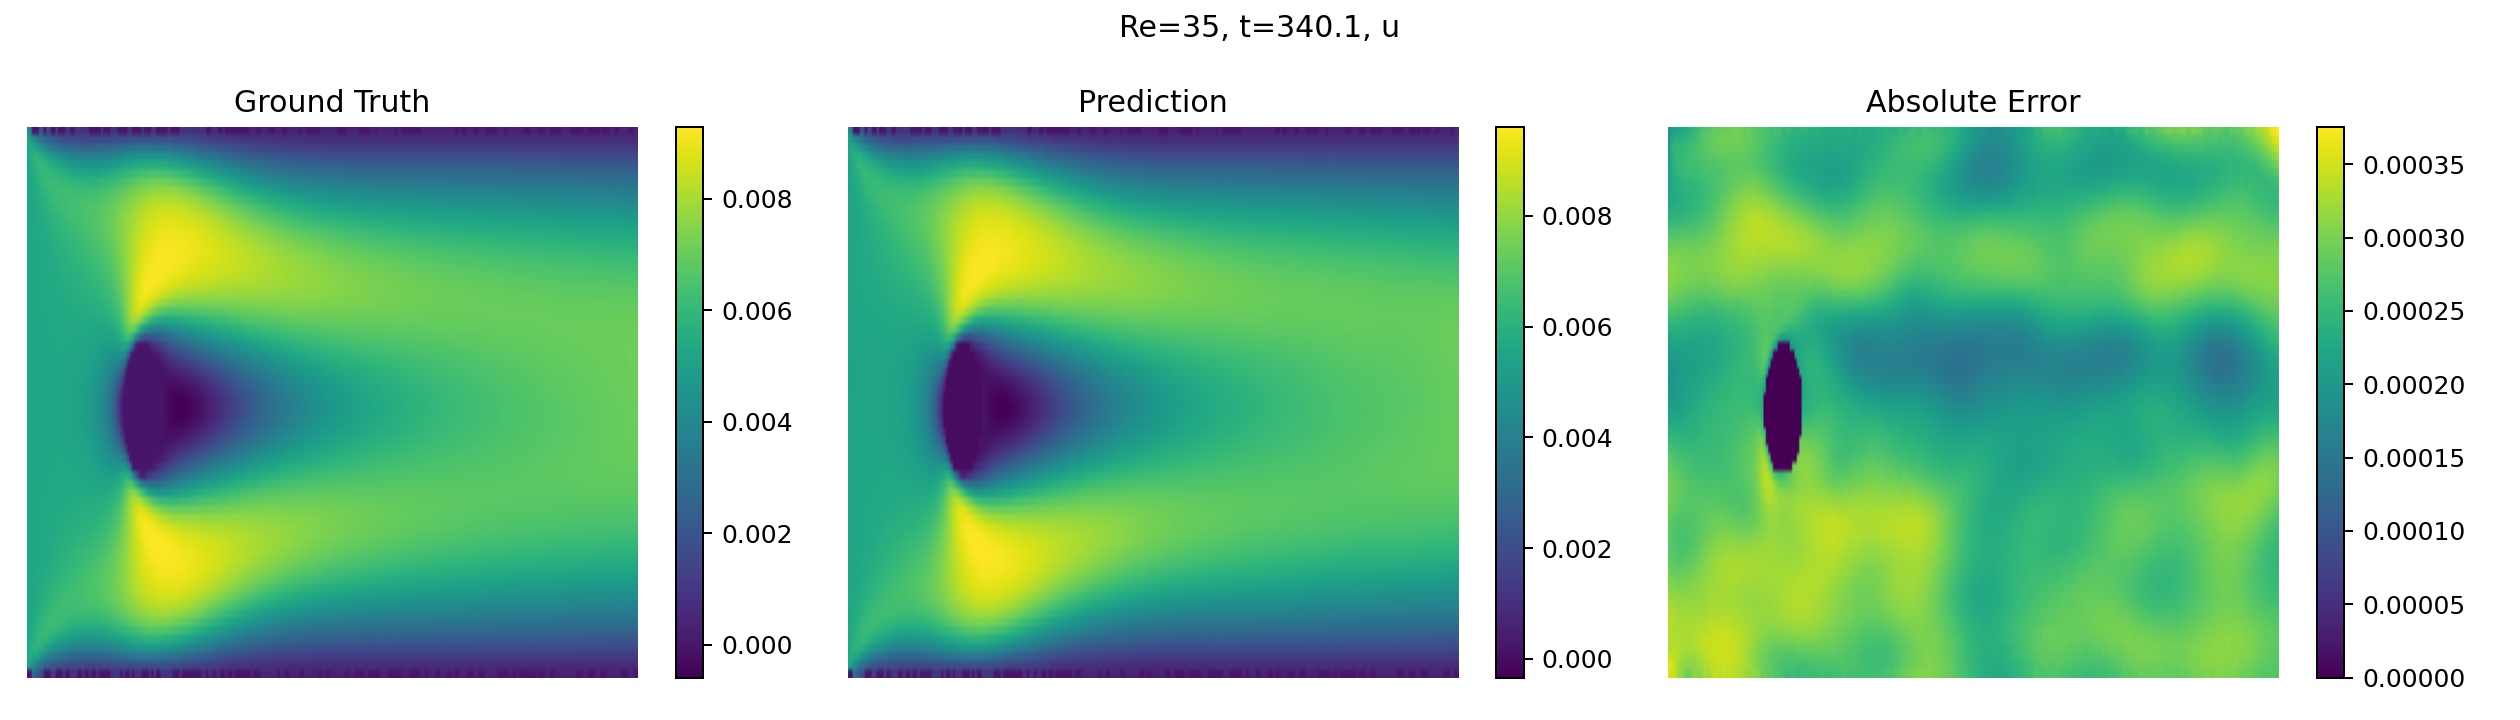

### step001_v

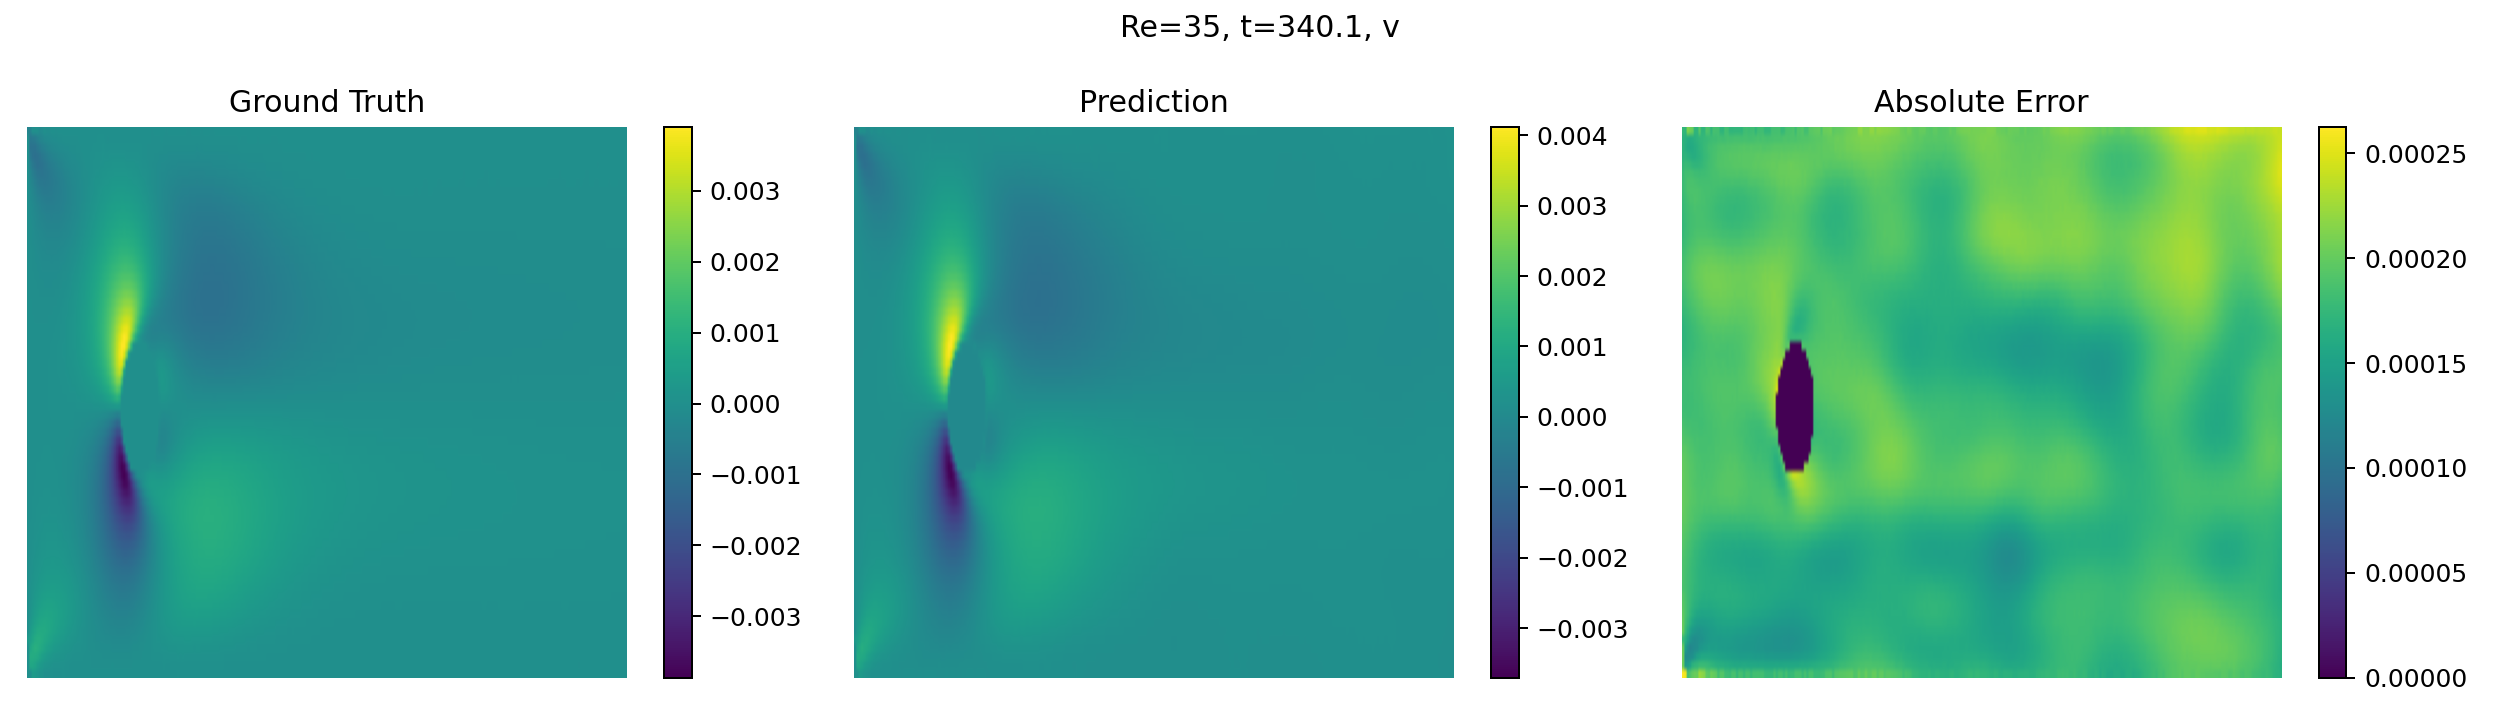

### step025_p

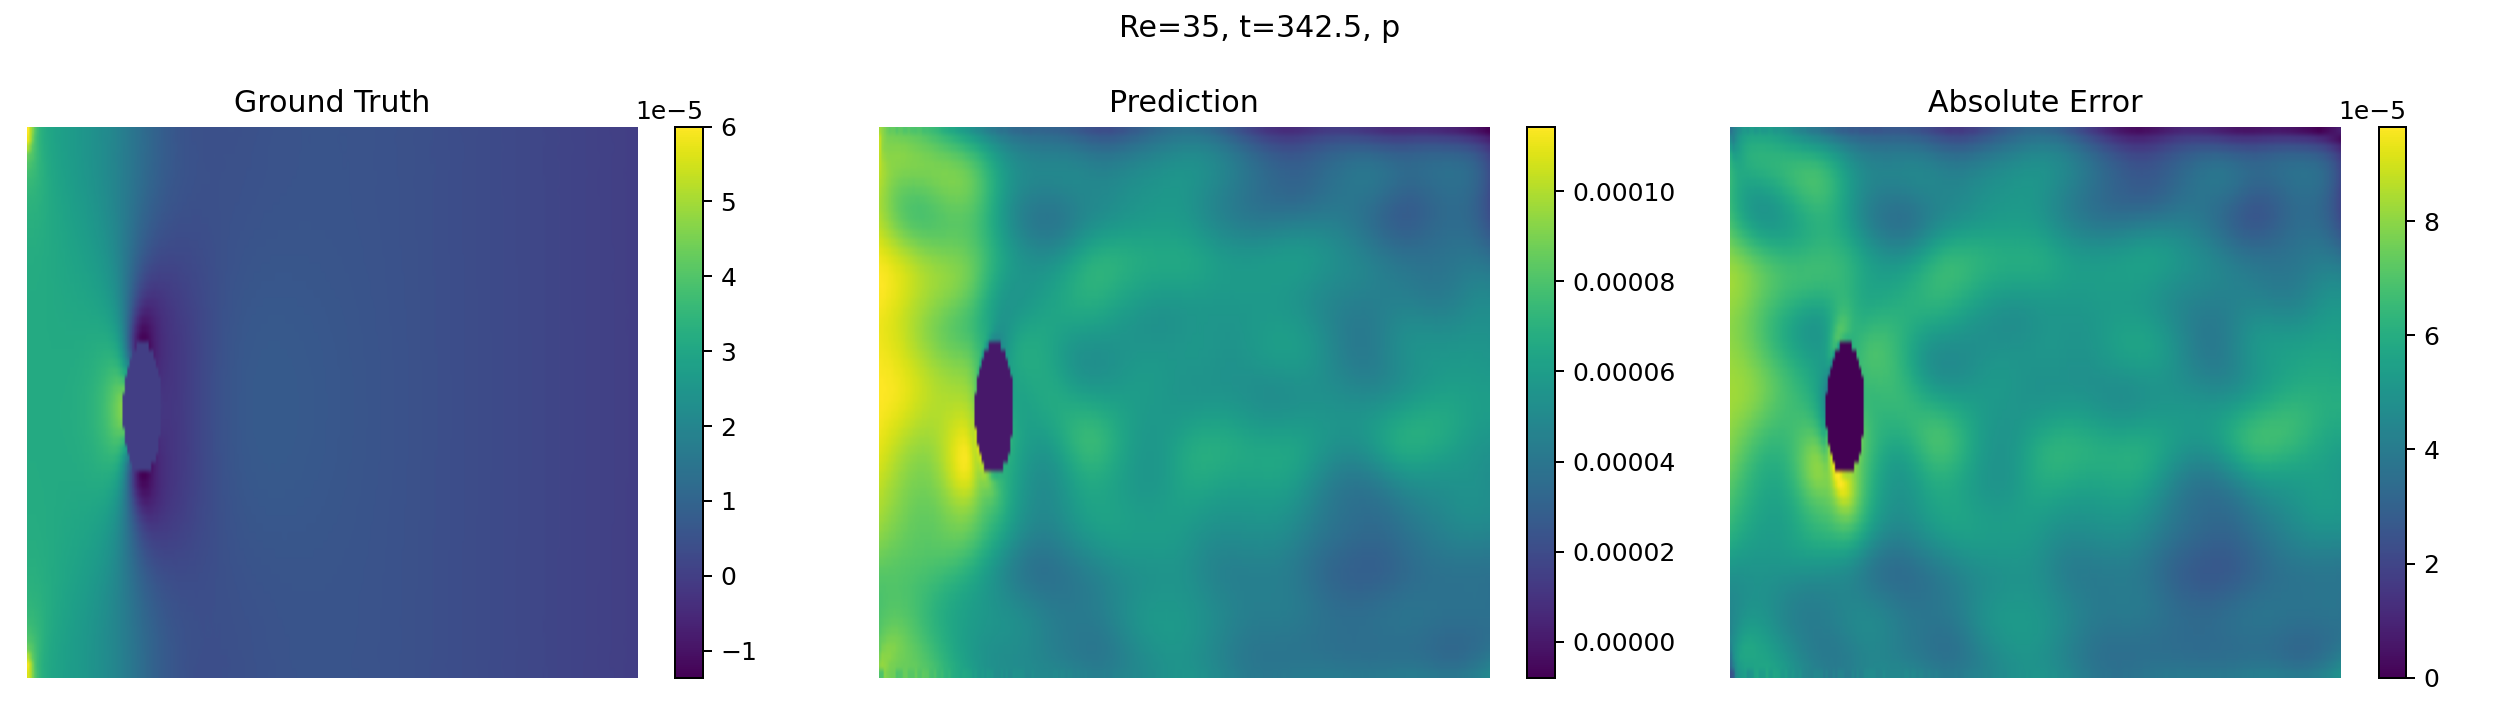

### step025_u

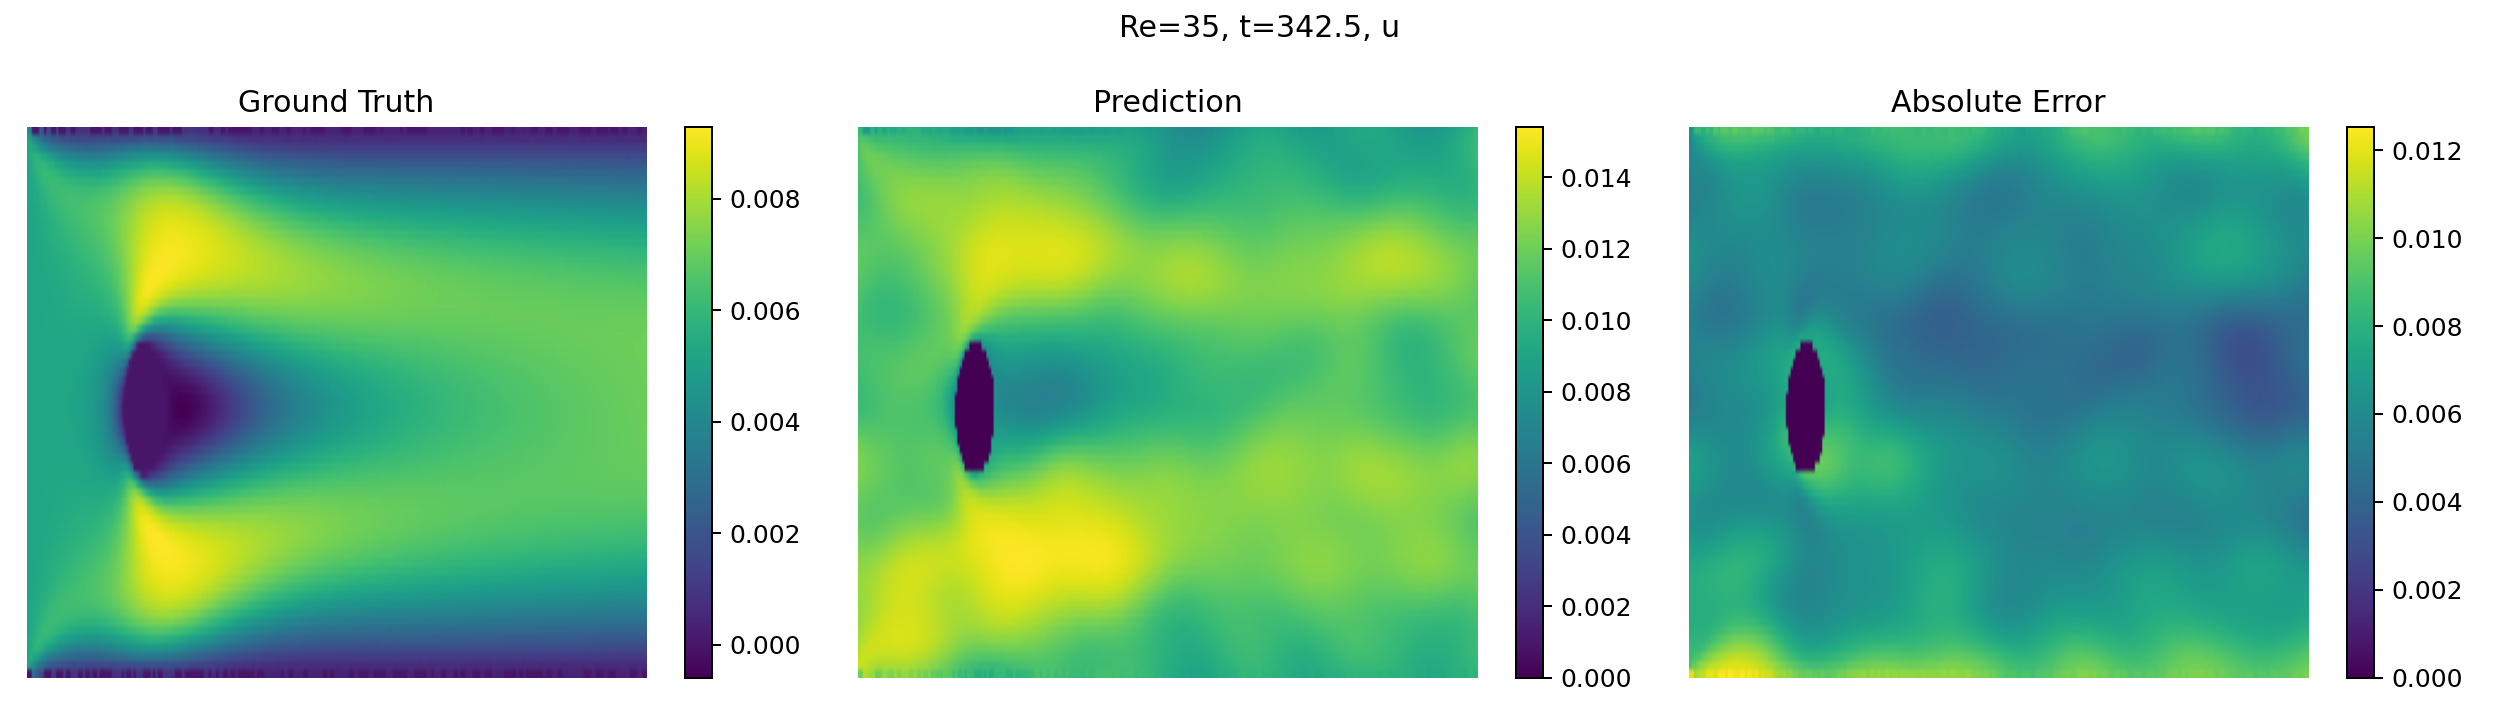

### step025_v

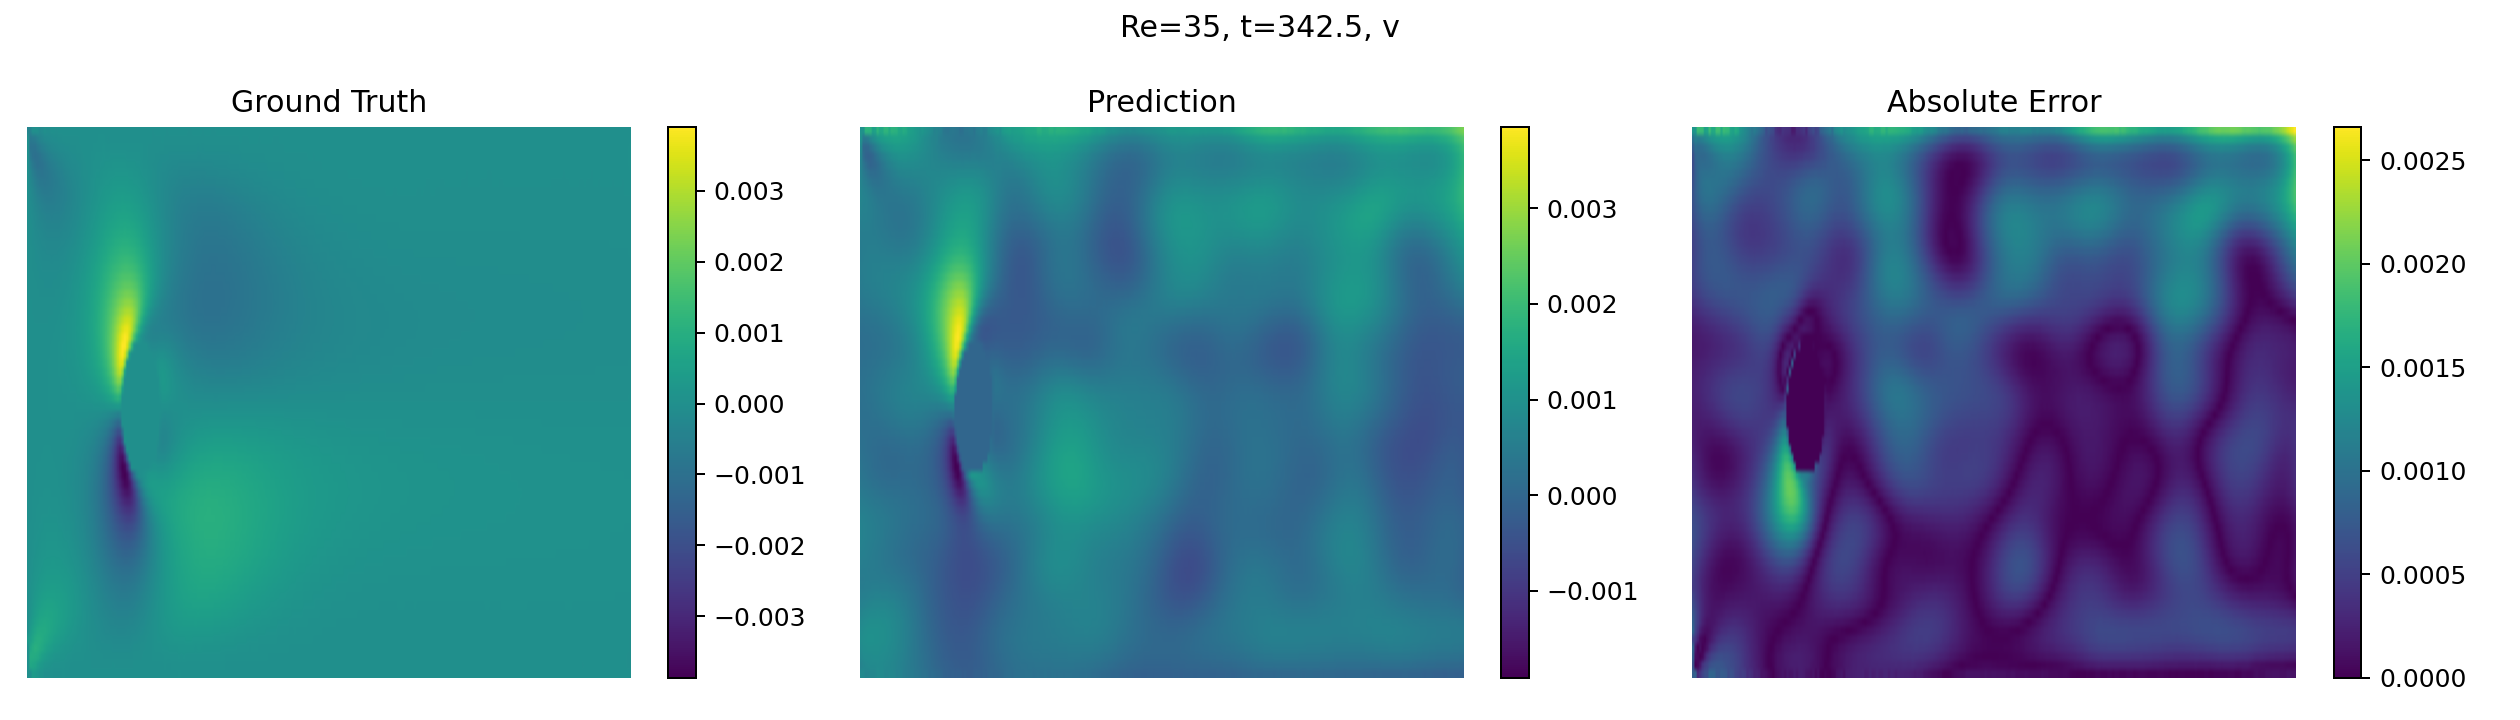

### step050_p

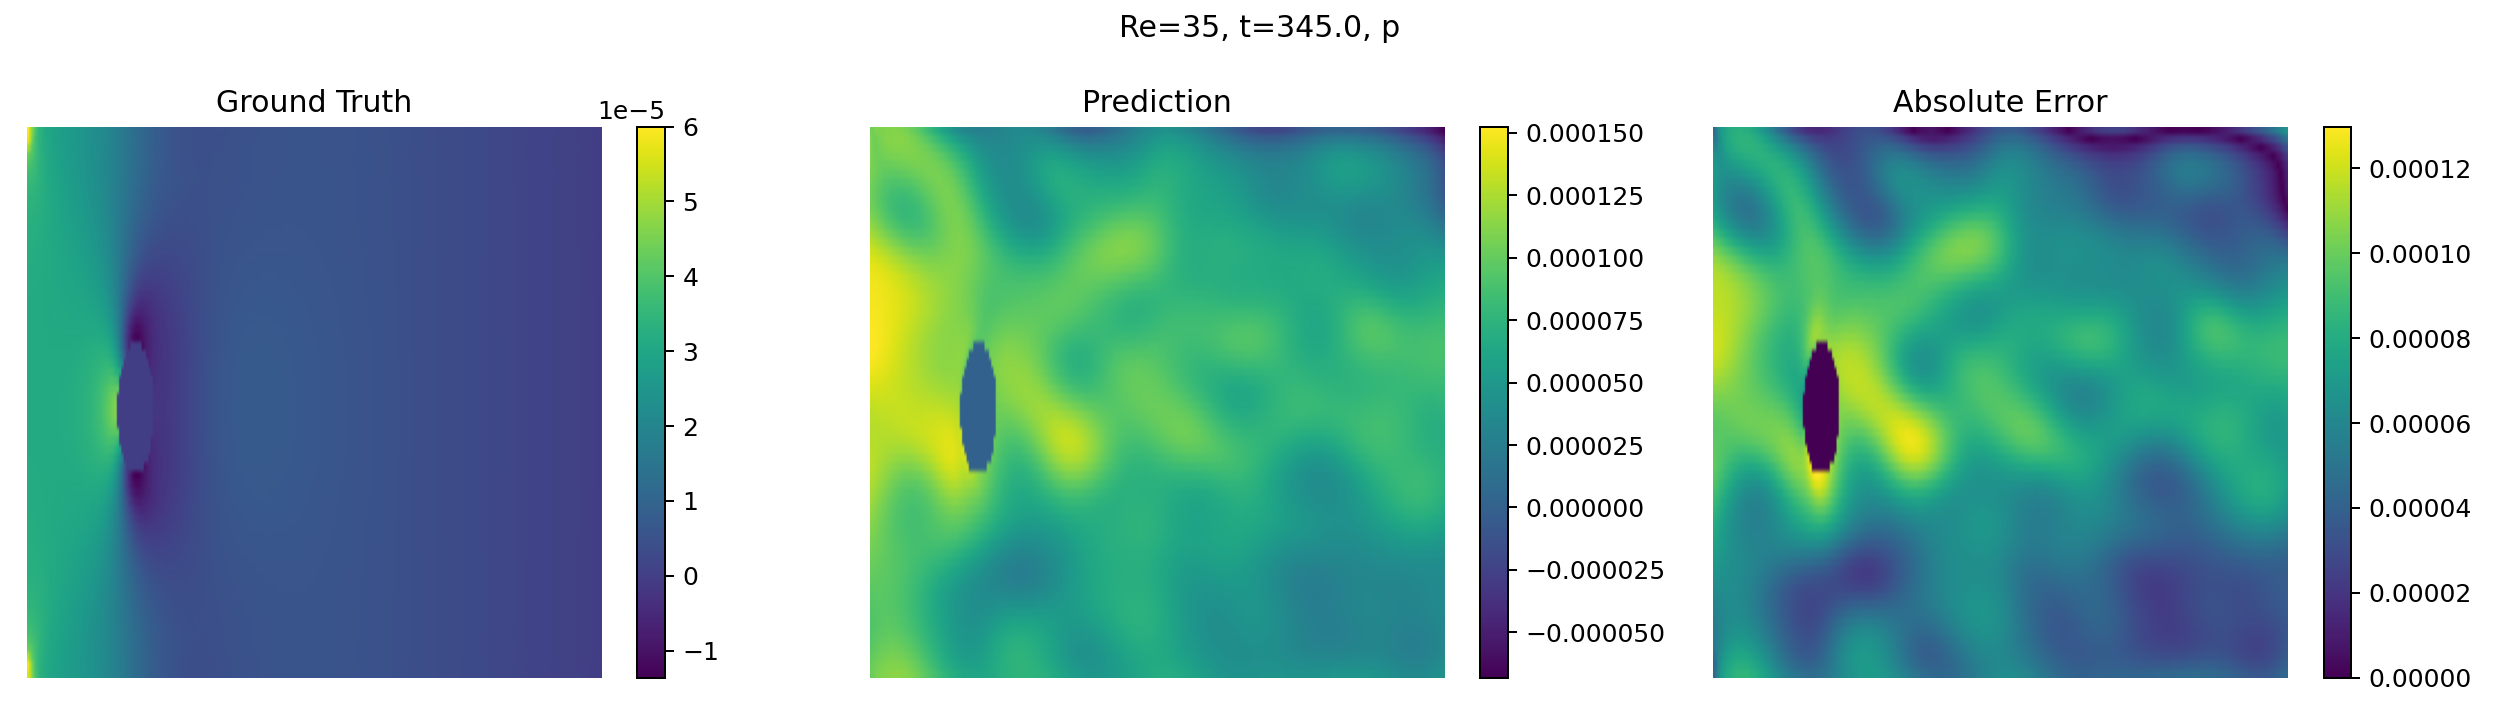

### step050_u

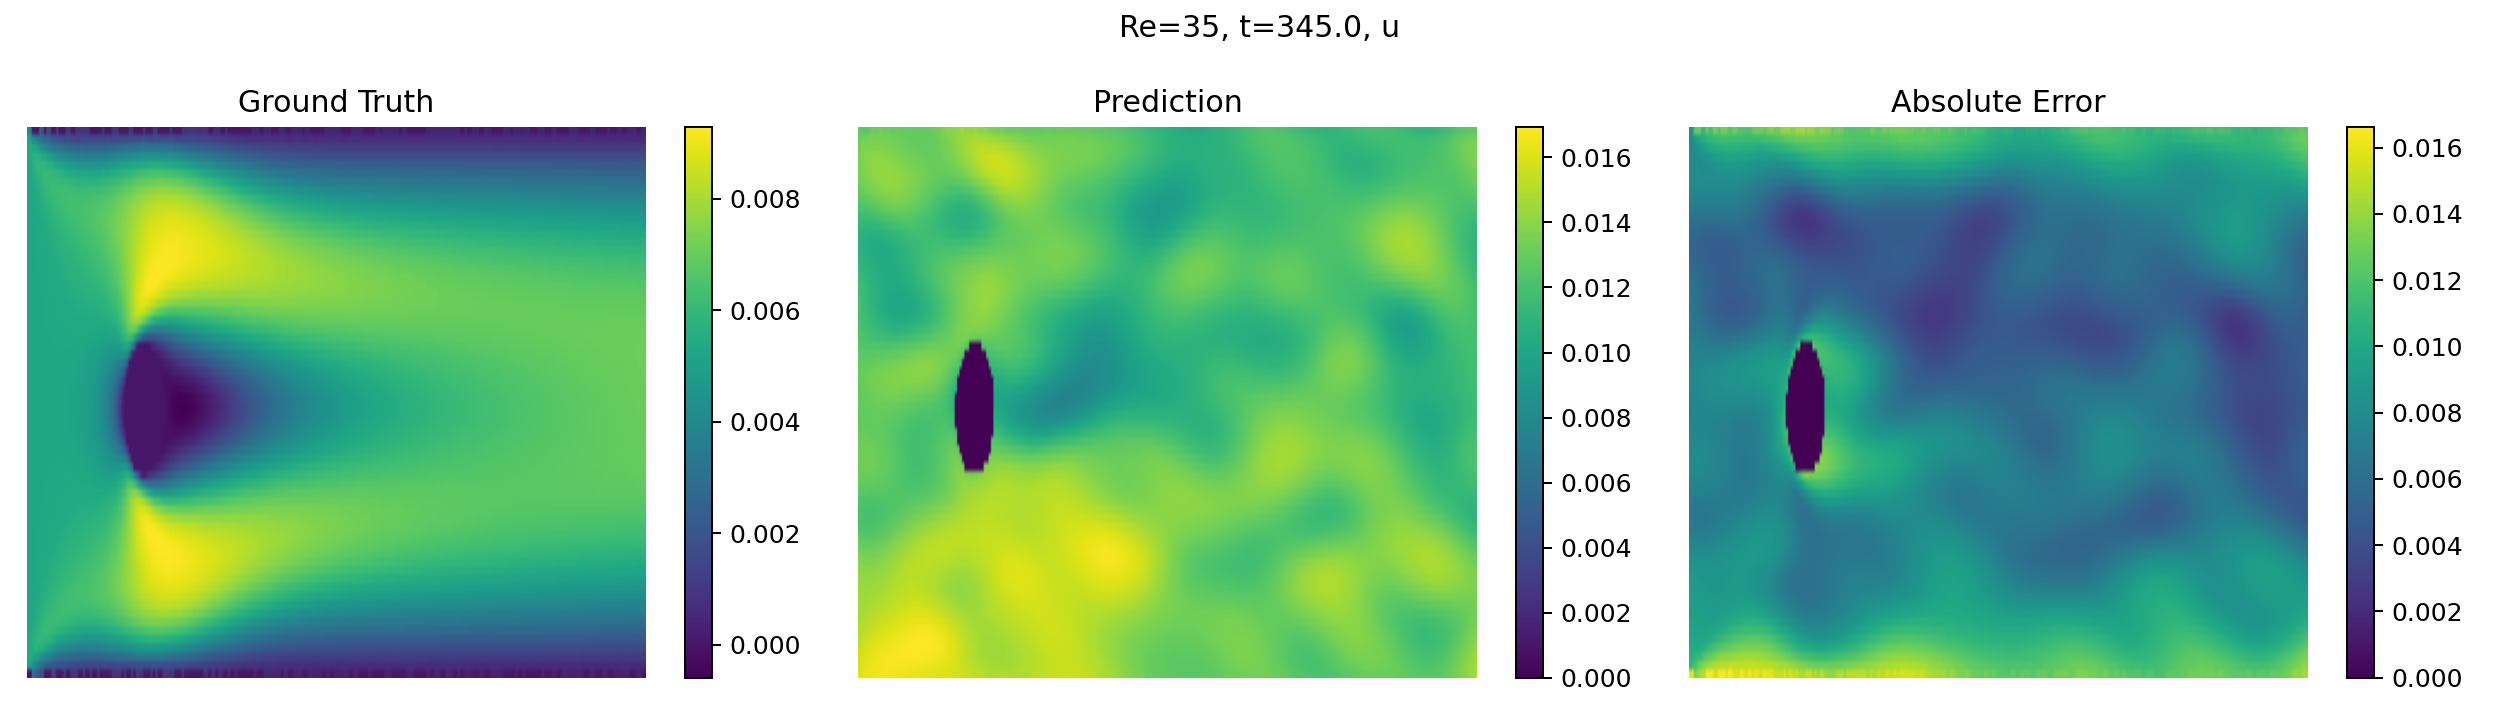

### step050_v

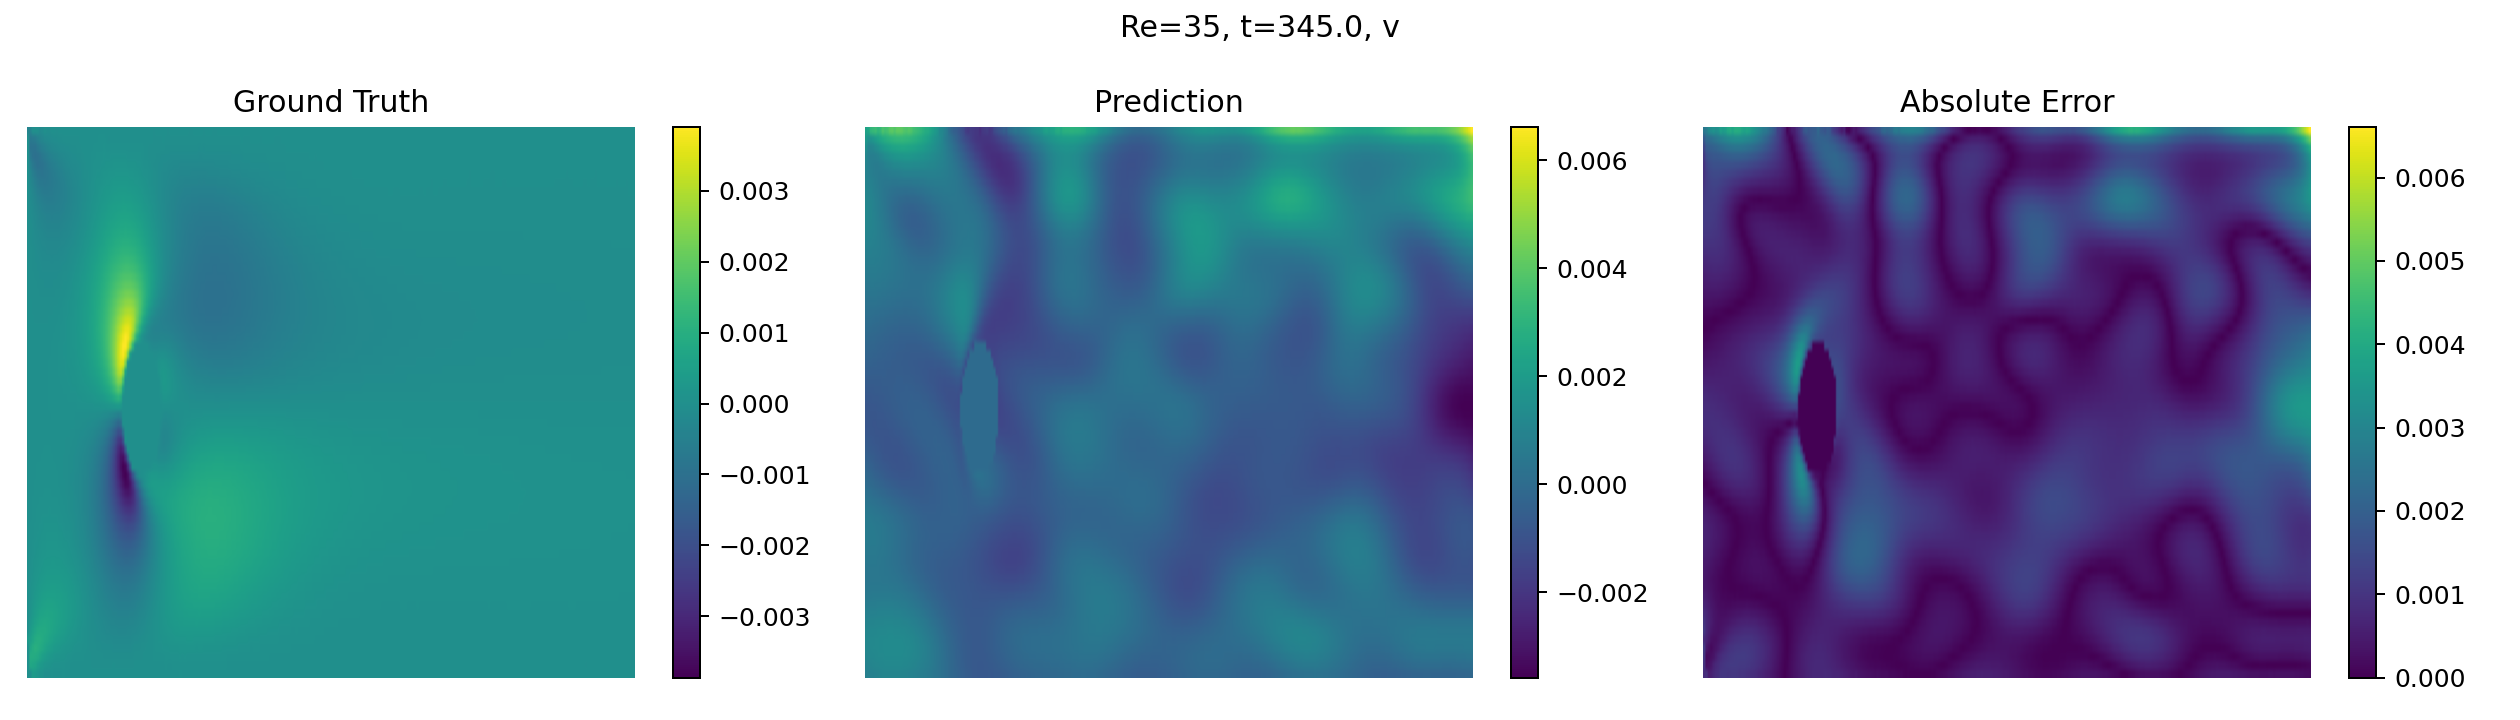

### step075_p

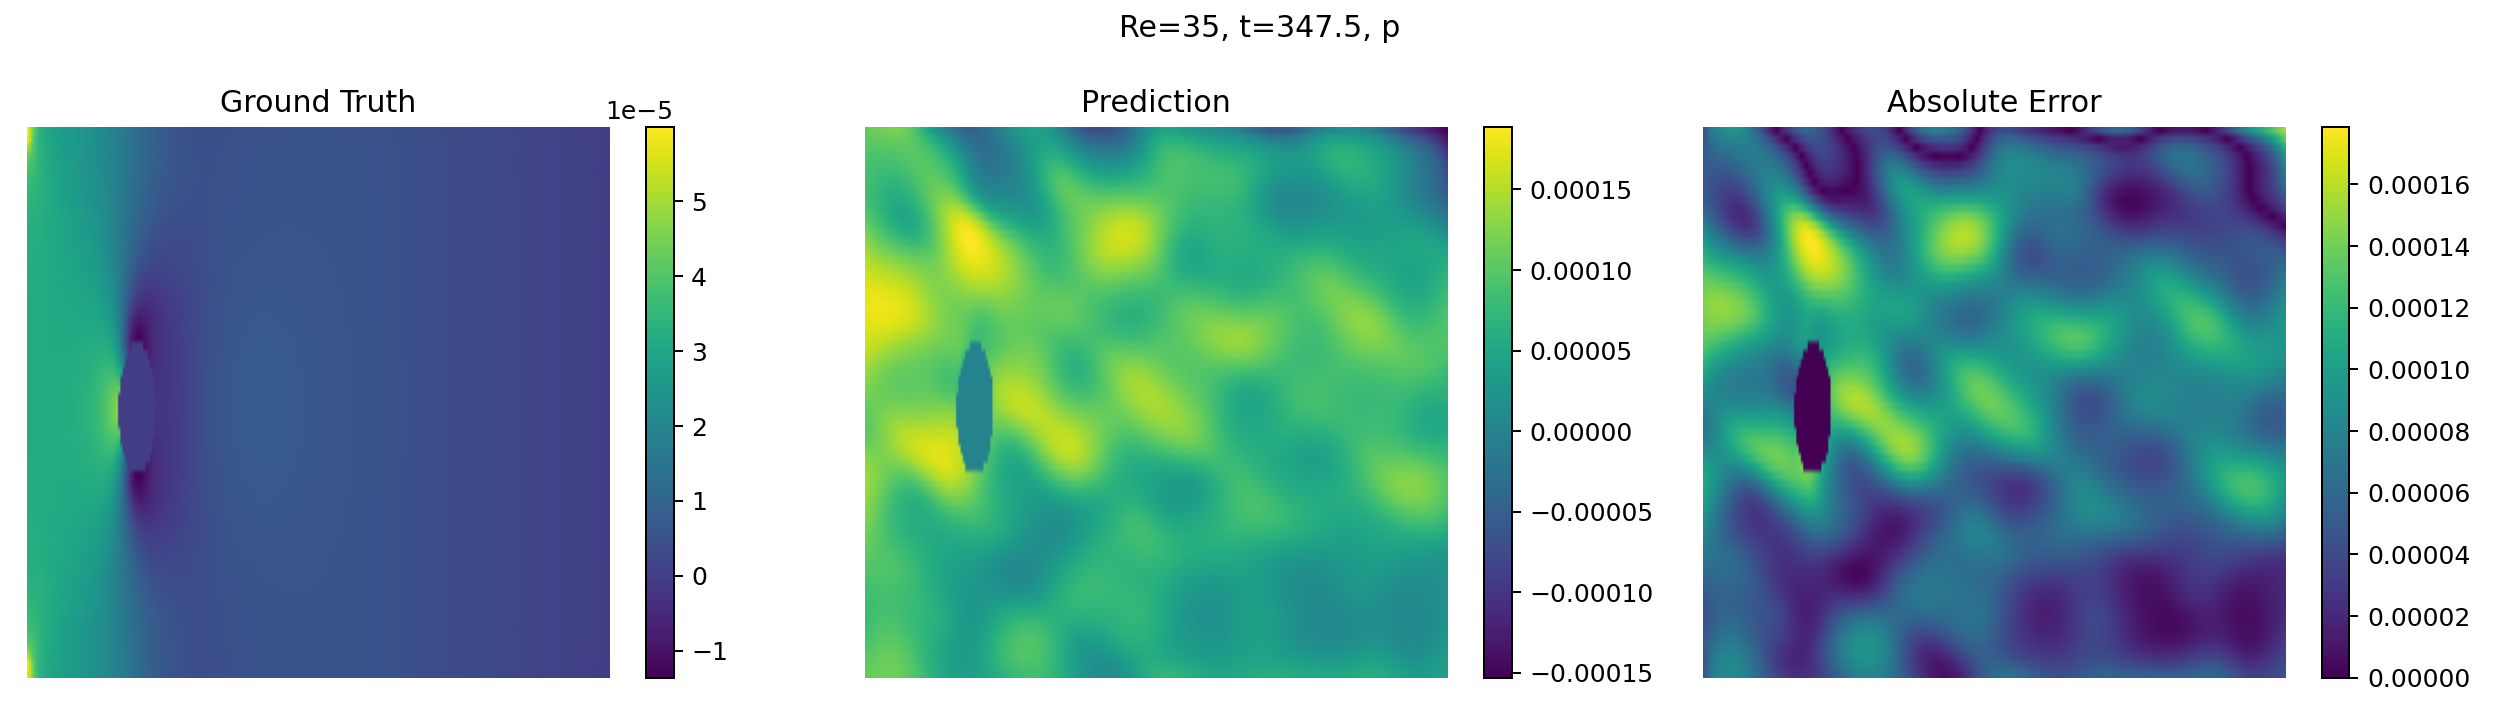

### step075_u

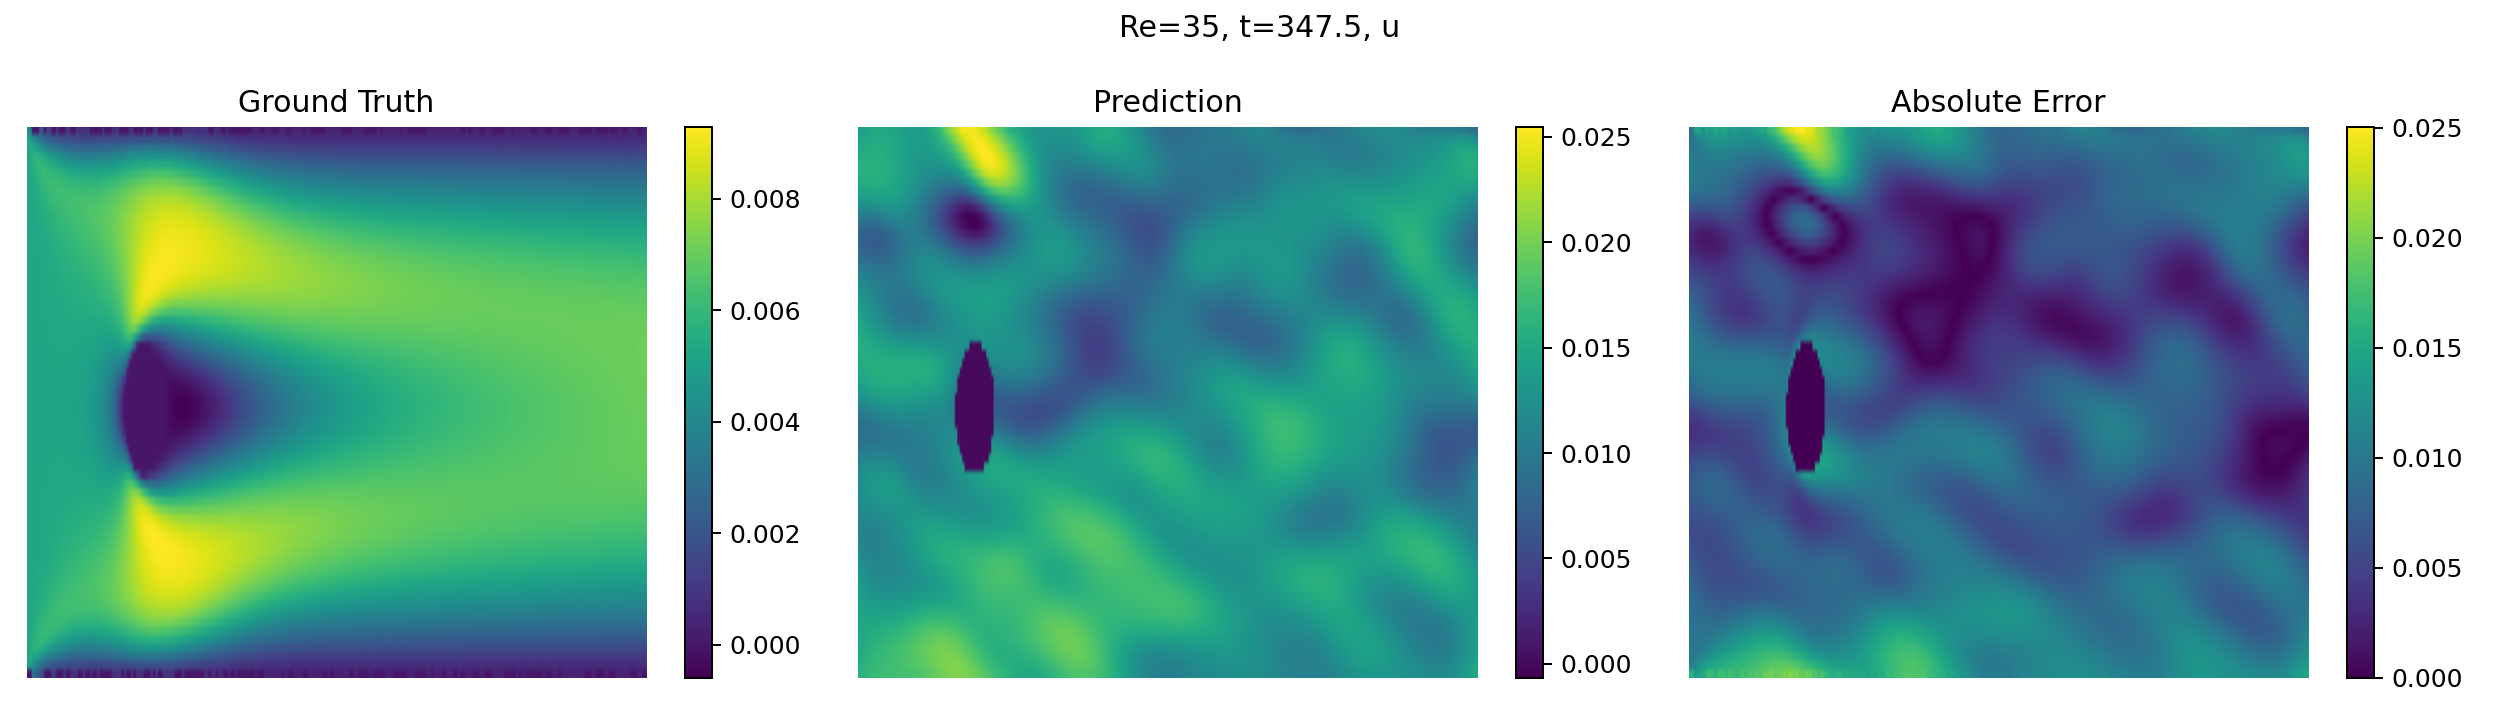

### step075_v

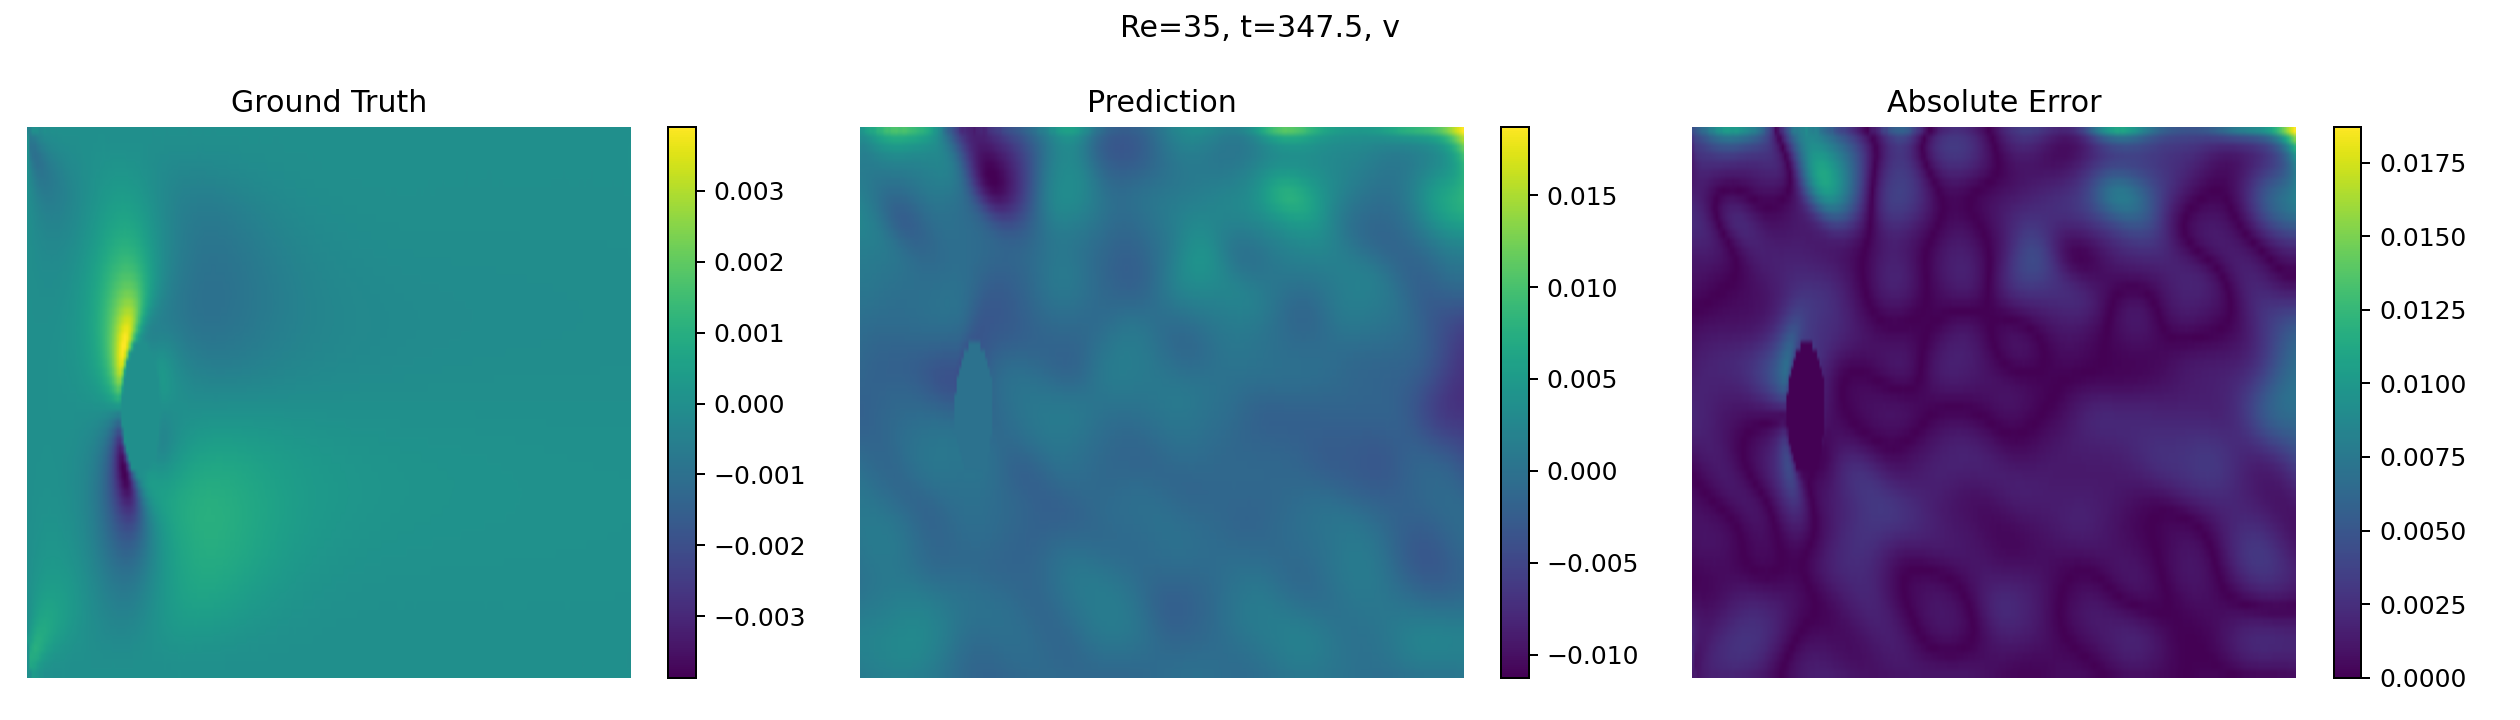

In [ ]:
SELECTED_RE=cfg["rollout"]["reynolds"][4]
plot_dir=result_dir/"plots"/f"Re{SELECTED_RE:g}"
images=sorted(plot_dir.glob("*.png"))
if not images: print("画像がありません:",plot_dir)
else:
 print(f"Re {SELECTED_RE:g}: {len(images)} images")
 for path in images:
  display(Markdown(f"### {path.stem}"))
  display(Image(filename=str(path)))


## 7. PT・ParaView出力の確認


In [8]:
for re_value in cfg["rollout"]["reynolds"]:
 status((result_dir/f"rollout_Re{re_value:g}.pt").exists(),f"full PT Re {re_value:g}")
 status((result_dir/f"rollout_prediction_Re{re_value:g}.pt").exists(),f"prediction PT Re {re_value:g}")
 pvd=result_dir/"vti"/f"Re{re_value:g}"/f"prediction_Re{re_value:g}.pvd"
 status(pvd.exists(),f"ParaView PVD Re {re_value:g}",pvd)


✅ full PT Re 35
✅ prediction PT Re 35
✅ ParaView PVD Re 35: /workspace/FNOV2/performance/results/ex002_baseline/interpolation/rollout/vti/Re35/prediction_Re35.pvd
✅ full PT Re 85
✅ prediction PT Re 85
✅ ParaView PVD Re 85: /workspace/FNOV2/performance/results/ex002_baseline/interpolation/rollout/vti/Re85/prediction_Re85.pvd
✅ full PT Re 135
✅ prediction PT Re 135
✅ ParaView PVD Re 135: /workspace/FNOV2/performance/results/ex002_baseline/interpolation/rollout/vti/Re135/prediction_Re135.pvd
✅ full PT Re 185
✅ prediction PT Re 185
✅ ParaView PVD Re 185: /workspace/FNOV2/performance/results/ex002_baseline/interpolation/rollout/vti/Re185/prediction_Re185.pvd
✅ full PT Re 235
✅ prediction PT Re 235
✅ ParaView PVD Re 235: /workspace/FNOV2/performance/results/ex002_baseline/interpolation/rollout/vti/Re235/prediction_Re235.pvd
